# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.4 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 5.1 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.8 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.2 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

fp16: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,15.39,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.97,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.89,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.99,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

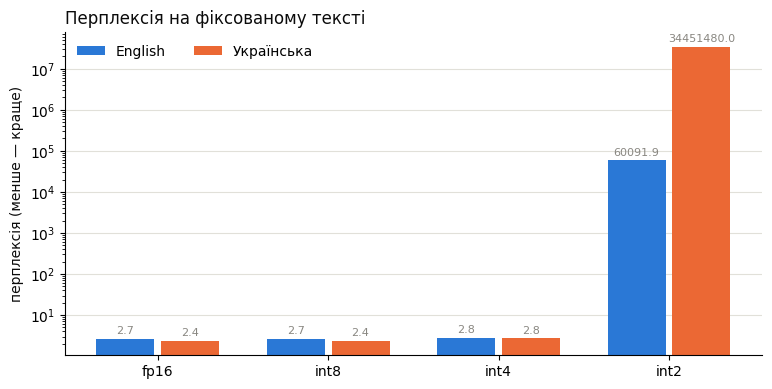

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "B", 3: "A", 4: "B", 5: "="}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,fp16
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 2, int4 краща: 2, однаково: 1


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

---
# Лабораторна робота №4. Виконання завдань

**Тема:** локальний запуск та оптимізація мовних моделей. У цій частині я використовую приклади лекції 5, а для власного проєкту обираю автомобільного помічника «АвтоДіагност». Теоретичні висновки наведені нижче, числові результати обчислюються клітинками під час фактичного запуску експериментів у Colab.

### 0.1.1. Чому модель неправильно рахує літери «р»?

Модель неправильно порахувала кількість літер «р» у слові «трансформер». Без міркувань вона відповіла, що літера зустрічається 1 раз, а з міркуваннями - 2 рази. Насправді правильна відповідь - 3.

На мою думку, це пов'язано з тим, що мовні моделі працюють із токенами, а не безпосередньо з окремими літерами. Тому вони можуть помилятися під час підрахунку символів навіть у режимі міркування.

Для перевірки я використав Python, який розбиває слово на окремі символи та підраховує кількість літер «р». Програма правильно визначила 3 входження. Отже, для таких завдань краще використовувати звичайний алгоритм, а не покладатися лише на відповідь мовної моделі.

In [ ]:
word = "трансформер"
print("Символи:", list(word))
print("Кількість р:", sum(char == "р" for char in word))
print("Токени моделі:", tokenizer.convert_ids_to_tokens(tokenizer.encode(word, add_special_tokens=False)))

Символи: ['т', 'р', 'а', 'н', 'с', 'ф', 'о', 'р', 'м', 'е', 'р']
Кількість р: 3
Токени моделі: ['ÑĤ', 'ÑĢÐ°Ð½', 'Ñģ', 'ÑĦÐ¾ÑĢÐ¼', 'ÐµÑĢ']


### 0.1.2. Як змінюються метрики від fp16 до int2?

Під час експерименту я порівняв чотири варіанти моделі: fp16, int8, int4 та int2.

Для fp16 перплексія становила 2,67 для англійської та 2,40 для української мови. В int8 вона практично не змінилася, а в int4 трохи зросла до 2,81 та 2,76 відповідно.

Найбільше погіршення відбулося при переході з int4 на int2. Перплексія англійською зросла до 60091,86, а українською - до 34451480. Це означає, що модель майже повністю втратила здатність правильно передбачати текст.

Метрики перекладу змінювалися не зовсім рівномірно. BLEU зріс із 23,71 для fp16 до 29,79 для int4, а chrF залишився приблизно на тому самому рівні. Але для int2 BLEU впав до 0,12, а chrF - до 0,19.

Отже, найбільший стрибок за всіма метриками спостерігався між int4 та int2. У цьому експерименті int4 ще зберігала прийнятну якість, тоді як int2 сильно погіршила результати.

In [ ]:
metrics=["перплексія, English","перплексія, Українська","chrF перекладу","BLEU перекладу"]
for key in metrics:
    vals=[float(summary.loc[v,key]) for v in VARIANTS]
    jumps=[vals[i+1]-vals[i] for i in range(len(vals)-1)]
    idx=max(range(len(jumps)), key=lambda i:abs(jumps[i]))
    print(key, dict(zip(VARIANTS,vals)), '| найбільша зміна:',list(VARIANTS)[idx], '→',list(VARIANTS)[idx+1],round(jumps[idx],2))

перплексія, English {'fp16': 2.67, 'int8': 2.67, 'int4': 2.81, 'int2': 60091.86} | найбільша зміна: int4 → int2 60089.05
перплексія, Українська {'fp16': 2.4, 'int8': 2.4, 'int4': 2.76, 'int2': 34451480.0} | найбільша зміна: int4 → int2 34451477.24
chrF перекладу {'fp16': 55.22, 'int8': 58.25, 'int4': 55.34, 'int2': 0.19} | найбільша зміна: int4 → int2 -55.15
BLEU перекладу {'fp16': 23.71, 'int8': 26.17, 'int4': 29.79, 'int2': 0.12} | найбільша зміна: int4 → int2 -29.67


### 0.1.3. Чи однаково зростає перплексія англійською та українською?

Перплексія англійською та українською мовами зростала по-різному. Для fp16 вона становила 2,67 для англійської та 2,40 для української. Після переходу на int4 показники зросли до 2,81 та 2,76 відповідно.

Найбільша різниця спостерігалася для int2. Перплексія англійською зросла до 60091,86, а українською - до 34451480. Отже, у моєму експерименті українська мова постраждала від сильної квантизації значно більше.

Це узгоджується з висновком лекції про те, що квантизація може сильніше погіршувати якість для мов, які менш представлені в навчальних даних. Водночас безпосередньо порівнювати абсолютні значення перплексії різних мов некоректно через особливості токенізації та різні тексти. Тому я порівнював зміну показників для кожної мови окремо.

In [ ]:
for lang in PPL_TEXT:
  a=records['fp16'][f'перплексія, {lang}']; b=records['int2'][f'перплексія, {lang}']
  print(lang, f'fp16={a:.2f}, int2={b:.2f}, зміна={(b/a-1)*100:.1f}%')

English fp16=2.67, int2=60091.86, зміна=2247490.0%
Українська fp16=2.40, int2=34451480.00, зміна=1435376080.6%


### 0.1.4. Чи збігається сліпе порівняння з автоматичними метриками?

Під час сліпого порівняння я обрав int4 у двох завданнях: написання листа викладачеві та пояснення квантизації. У першому випадку відповідь була коротшою та більше відповідала запиту. Модель fp16 я обрав для пояснення, чому небо блакитне, та складання плану підготовки до іспиту. У завданні з написанням Python-функції для перевірки паліндрома обидві відповіді були майже однаковими.

Загалом fp16 отримала 2 голоси, int4 також 2, а один результат був однаковим.

Автоматичні метрики показали, що int4 має трохи вищий chrF (55,34 проти 55,22) та помітно вищий BLEU (29,79 проти 23,71). Однак під час ручного порівняння я не помітив однозначної переваги int4.

На мою думку, це пов'язано з тим, що автоматичні метрики оцінювали переклади, а сліпе порівняння проводилося на інших завданнях. За п'ятьма відповідями суттєвої різниці між fp16 та int4 я не виявив.

In [ ]:
if all(v in ('A','B','=') for v in VOTES.values()):
 counts={'fp16':0,'int4':0,'однаково':0}
 for i,vote in VOTES.items():
  choice='однаково' if vote=='=' else dict(zip('AB',BLIND_ORDER[i-1]))[vote]
  counts[choice]+=1
 print('Результат ручного порівняння:',counts)
 print('Автоматичні метрики:',summary[['chrF перекладу','BLEU перекладу']].loc[['fp16','int4']])
else: print('Оцінювання ще не завершено. Заповніть VOTES у вихідній секції 2.5.')

Результат ручного порівняння: {'fp16': 2, 'int4': 2, 'однаково': 1}
Автоматичні метрики:       chrF перекладу  BLEU перекладу
fp16           55.22           23.71
int4           55.34           29.79


### 0.1.5. Як BLEU і chrF реагують на правильний переклад іншими словами?

Під час експерименту я знайшов приклад, коли модель правильно переклала речення, але використала інші слова, ніж в еталоні.

Оригінал: "If the server does not respond, restart it and check the logs."

Еталон: "Якщо сервер не відповідає, перезапустіть його й перевірте логи."

Переклад моделі: "Якщо сервер не відповідає, перезапустіть його і перевірте журнал."

За змістом переклад правильний, але замість слова "логи" модель використала "журнал". Через цю відмінність BLEU становив 60,8, а chrF - 83,7.

BLEU сильніше реагує на відмінності між словами та їхніми послідовностями, тоді як chrF порівнює символьні послідовності. Тому chrF у цьому випадку вищий. Це показує, що автоматичні метрики не завжди повністю відображають правильність перекладу за змістом.

In [ ]:
for i,(source,reference) in enumerate(TRANSLATION):
 pred=records['fp16']['переклади'][i]
 if pred.strip()!=reference.strip():
  b=bleu.compute(predictions=[pred],references=[[reference]])['score']
  c=chrf.compute(predictions=[pred],references=[[reference]])['score']
  print('Джерело:',source)
  print('Еталон:',reference)
  print('Модель:',pred)
  print('BLEU:',round(b,1),'chrF:',round(c,1))
  print()

Джерело: The meeting has been moved to Thursday at three o'clock.
Еталон: Зустріч перенесли на четвер на третю годину.
Модель: Зустріч була перенесена на четвер, о 15 годин.
BLEU: 10.0 chrF: 49.9

Джерело: Please send me the report by the end of the day.
Еталон: Будь ласка, надішліть мені звіт до кінця дня.
Модель: Надішліть мені звіт до кінця дня.
BLEU: 52.7 chrF: 73.1

Джерело: The library is closed on Sundays and public holidays.
Еталон: Бібліотека не працює в неділю та у святкові дні.
Модель: Бібліотека закривається у неділі та дні відпочинку.
BLEU: 6.4 chrF: 36.7

Джерело: Our team fixed the bug, but the tests are still failing.
Еталон: Наша команда виправила помилку, але тести все ще не проходять.
Модель: Наша команда виправила баг, але тестування все ще не працюють.
BLEU: 24.8 chrF: 60.7

Джерело: It is going to rain tomorrow, so take an umbrella.
Еталон: Завтра буде дощ, тож візьміть парасольку.
Модель: Завтра піде дощ, тому взміть засіб.
BLEU: 13.1 chrF: 37.1

Джерело: The new

### 0.1.6. Наскільки зменшилась пам’ять і чи зросла швидкість?

Під час експерименту я порівняв використання пам'яті та швидкість генерації чотирьох варіантів моделі.

Для fp16 модель займала 8,04 GB пам'яті, для int8 - 4,42 GB, для int4 - 2,73 GB, а для int2 - 1,81 GB. Отже, порівняно з fp16 використання пам'яті зменшилося приблизно у 1,82 раза для int8, у 2,94 раза для int4 та у 4,44 раза для int2.

Зменшення не дорівнює точно 2, 4 та 8 разам, оскільки не всі компоненти моделі квантизуються. Частина даних залишається у вищій точності, а для квантизації також потрібні додаткові метадані.

При цьому швидкість генерації не зросла. Для fp16 вона становила 15,39 токенів/с, для int8 - 5,97, для int4 - 2,89, а для int2 - 2,99 токенів/с.

Таким чином, квантизація дозволила суттєво зменшити використання пам'яті, але в моєму експерименті сповільнила генерацію. Це може бути пов'язано з додатковими операціями деквантизації та особливостями реалізації обчислень на GPU.

In [ ]:
base=records['fp16']['памʼять моделі, GB']
for name,r in records.items():
 print(f"{name}: пам'ять={r['памʼять моделі, GB']:.2f} GB, зменшення={base/r['памʼять моделі, GB']:.2f}x, швидкість={r['tokens/s']:.2f} tok/s")

fp16: пам'ять=8.04 GB, зменшення=1.00x, швидкість=15.39 tok/s
int8: пам'ять=4.42 GB, зменшення=1.82x, швидкість=5.97 tok/s
int4: пам'ять=2.73 GB, зменшення=2.94x, швидкість=2.89 tok/s
int2: пам'ять=1.81 GB, зменшення=4.44x, швидкість=2.99 tok/s


### 0.1.7. Чому Base-модель продовжує питання і як отримати відповідь?

Base-модель навчена передбачати наступні токени та продовжувати текст, а не обов'язково виконувати інструкції користувача. Тому на питання «Яка столиця Франції?» вона почала генерувати нові питання замість відповіді.

Щоб отримати правильну відповідь, я змінив промпт і додав приклад у форматі «питання - відповідь»:

Питання: Яка столиця Франції?  
Відповідь: Париж

Питання: Яка столиця Італії?  
Відповідь:

Після цього модель правильно відповіла «Рим». Однак далі вона продовжила генерувати нове питання про столицю Польщі.

Отже, навіть Base-модель може правильно відповідати на питання, якщо задати їй відповідний формат тексту. Проте вона все одно сприймає завдання як продовження тексту, а не як діалог з користувачем.

In [ ]:
base_prompt = "Питання: Яка столиця Франції?\nВідповідь: Париж\n\nПитання: Яка столиця Італії?\nВідповідь:"
print('Промпт:',base_prompt)
print('Результат Base:', generate_raw(BASE_MODEL,base_prompt, max_tokens=28))

Промпт: Питання: Яка столиця Франції?
Відповідь: Париж

Питання: Яка столиця Італії?
Відповідь:
Результат Base:  Рим

Питання: Яка столиця Польщі?
Відповідь: В


### 0.1.8. Час і кількість токенів у режимах з міркуваннями та без них

Під час експерименту я порівняв роботу моделі з увімкненим і вимкненим режимом міркування на задачі про кількість яблук у кошику.

Без міркувань модель використала 252 токени за 2,27 секунди, а з міркуваннями - 566 токенів за 5,02 секунди. Отже, режим міркування потребував на 314 токенів і 2,75 секунди більше.

В обох випадках модель правильно відповіла, що в кошику залишилося 9 яблук. Тому на цій простій задачі режим міркування не покращив результат, але збільшив витрати часу та токенів.

Модель може міркувати англійською, навіть якщо питання поставлене українською, оскільки значна частина прикладів міркувань у навчальних даних представлена англійською мовою. Мова внутрішніх міркувань не обов'язково збігається з мовою запиту.

In [ ]:
prompt = "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, а потім зʼїла 2 яблука. Скільки яблук у кошику?"
measure_think={}
for think_mode in (False,True):
 resp=chat(INSTRUCT_MODEL,prompt,think=think_mode)
 measure_think[think_mode]=(resp.get('eval_count',0),resp.get('eval_duration',0)/1e9)
 print('think=',think_mode,'токенів=',measure_think[think_mode][0],'секунд=',round(measure_think[think_mode][1],2),'відповідь=',resp['message']['content'])
a,b=measure_think[False],measure_think[True]
print('Додатково:',b[0]-a[0],'токенів та',round(b[1]-a[1],2),'с')

think= False токенів= 252 секунд= 2.27 відповідь= Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$
think= True токенів= 566 секунд= 5.02 відповідь= Після того як Марія поклала 2 пакети по 4 яблука, у кошику стало 3 + (2 × 4) = 11 яблука. Потім вона з'їла 2 яблука, тому залишилося 11 − 2 = 9 яблука.

**Відповідь: 9**
Додатково: 314 токенів та 2.75 с


### 0.1.9. Приклад, де міркування допомагають, а без них модель помиляється

Для перевірки я протестував декілька математичних задач у двох режимах моделі Qwen3-1.7B: без міркувань та з міркуваннями.

Мені вдалося знайти задачу, на якій результати відрізнялися:

«У трьох коробках по 6 деталей. 4 деталі зламали, ще 3 додали. Скільки справних деталей тепер?»

Правильна відповідь: 3 × 6 − 4 + 3 = 17 деталей.

Без міркувань модель відповіла, що залишилося 14 справних деталей. Вона правильно порахувала початкову кількість і відняла зламані деталі, але не врахувала 3 додані.

З увімкненим режимом міркування модель врахувала всі дії та правильно відповіла, що залишилося 17 справних деталей.

Отже, у цьому випадку режим міркування допоміг моделі правильно виконати багатокрокове обчислення. Водночас він потребував більше токенів: 1826 проти 217 без міркувань.

In [ ]:
candidates=[
 ('На полиці було 5 книжок, я купив ще 3 набори по 4 книжки і подарував 6. Скільки залишилося?','11'),
 ('У кімнаті 4 столи, на кожному по 3 яблука. 5 яблук з’їли. Скільки залишилося?','7'),
 ('У трьох коробках по 6 деталей. 4 деталі зламали, ще 3 додали. Скільки справних деталей тепер?','17'),
 ('У парку 18 дерев, третину зрубали, потім посадили 5 нових. Скільки дерев стало?','17'),
]
found=[]
import re
for prompt,right in candidates:
 answers={}
 for mode in (False,True):
  data=chat(INSTRUCT_MODEL,prompt,think=mode,max_tokens=1400)
  answers[mode]=data['message']['content']
 def match(s):
  nums=re.findall(r'(?<!\d)\d+(?!\d)',s)
  return bool(nums) and nums[-1]==right
 if match(answers[True]) and not match(answers[False]):
  found.append((prompt,right,answers))
 print('Задача:',prompt)
 print('Без міркувань:',answers[False])
 print('З міркуваннями:',answers[True])
 print('Еталон:',right)
 print()
print('Знайдено прикладів:',len(found),'(евристика: останнє число у відповіді)')

Задача: На полиці було 5 книжок, я купив ще 3 набори по 4 книжки і подарував 6. Скільки залишилося?
Без міркувань: Підсумуємо:

- На полиці було **5** книжок.
- Купив **3 набори по 4 книжки** → **3 × 4 = 12** книжок.
- Подарував **6** книжок.

Таким чином:

**5 + 12 = 17** — загальна кількість книжок.

**17 - 6 = 11** — залишилося книжок.

**Відповідь: 11** книжок залишилося.
З міркуваннями: Після куплення 3 наборів по 4 книжки (що відповідатиме 3 × 4 = 12 книжкам) і додавання до початкової кількості 5 книжок, отримаємо загальну кількість: 5 + 12 = 17. Після того як він подарував 6 книжок, залишилося: 17 - 6 = 11. 

**Відповідь:** 11 книжок залишилося.
Еталон: 11

Задача: У кімнаті 4 столи, на кожному по 3 яблука. 5 яблук з’їли. Скільки залишилося?
Без міркувань: У кімнаті 4 столи, на кожному по 3 яблука — це:

$$
4 \text{ столи} \times 3 \text{ яблука на стол} = 12 \text{ яблука}
$$

Потім з'їли 5 яблук.

Тому, скільки залишилося:

$$
12 - 5 = 7
$$

**Відповідь: 7 яблука залишилося.**

In [ ]:
prompt = (
    "У трьох коробках по 6 деталей. "
    "4 деталі зламали, ще 3 додали. "
    "Скільки справних деталей тепер?"
)

for mode in (False, True):
    result = chat(
        INSTRUCT_MODEL,
        prompt,
        think=mode,
        max_tokens=4000
    )

    print(f"Режим міркування: {mode}")
    print("Відповідь:", result["message"]["content"])
    print("Токенів:", result["eval_count"])
    print("-" * 40)

Режим міркування: False
Відповідь: Розглянемо задачу:

- У трьох коробок по 6 деталей → загальна кількість деталей:  
  $ 3 \times 6 = 18 $ деталей.

- 4 деталі зламали → залишилося:  
  $ 18 - 4 = 14 $ деталей.

- 3 додали → тепер у кожної коробки по 6 деталей, але 4 з них зламані, тому:

  - У трьох коробках:  
    $ 3 \times 6 = 18 $ деталей.

  - З них 4 зламані → залишилося:  
    $ 18 - 4 = 14 $ деталей.

**Відповідь:**  
$ \boxed{14} $ справних деталей.
Токенів: 217
----------------------------------------
Режим міркування: True
Відповідь: Після розгляду задачі:

1. **Підсумок початкової ситуації**:  
   - У трьох коробках по 6 деталей → загальна кількість деталей:  
     $ 3 \times 6 = 18 $ деталей.

2. **Після злому 4 деталей**:  
   - Кількість справних деталей:  
     $ 18 - 4 = 14 $ деталей.

3. **Додано 3 нові деталі**:  
   - Нехай нові деталі є справними (найбільш вероятно, оскільки не зазначені негативні властивості).  
   - Загальна кількість справних деталей:  
     $

### 0.1.10. Навіщо temperature=0 та seed=1?

Такі налаштування зменшують випадковість генерації, щоб повторні запуски були максимально порівнюваними. `temperature=0` зазвичай відповідає жадібному вибору токенів, а фіксований `seed` додатково фіксує випадковість, якщо вона є. Повної побітової повторюваності між різними пристроями це не гарантує.

### 0.1.11. Чому fp16, а не bf16 на T4?

У другій секції лабораторної я використовував fp16 замість bf16, оскільки експерименти виконувалися на відеокарті NVIDIA Tesla T4 з архітектурою Turing та compute capability 7.5.

Tesla T4 підтримує прискорені обчислення FP16, але не має нативної апаратної підтримки BF16. Під час перевірки функція `torch.cuda.is_bf16_supported()` повернула True. Це пояснюється тим, що PyTorch за замовчуванням враховує також можливість програмної підтримки BF16.

Тому для експериментів я обрав fp16, який краще відповідає апаратним можливостям T4.

In [ ]:
print("GPU:", torch.cuda.get_device_name())
print("Compute capability:", torch.cuda.get_device_capability())
print("BF16 з емуляцією:", torch.cuda.is_bf16_supported())
print("Нативна підтримка BF16:", torch.cuda.is_bf16_supported(including_emulation=False))

GPU: Tesla T4
Compute capability: (7, 5)
BF16 з емуляцією: True
Нативна підтримка BF16: False


### 0.1.12. Скільки параметрів у 4B та скільки займає fp16?

За карткою моделі `Qwen3-4B-Instruct-2507` вона має приблизно 4,0 млрд параметрів. У fp16 кожен параметр займає 2 байти, тому теоретичний розмір лише ваг близько 8,0 GB. Реальне число з демонстрації може відрізнятися через формат тензорів та облік пам’яті.

In [ ]:
parameters=4.0e9
print('Теорія fp16, GB:',parameters*2/1e9)
print('У таблиці (GB):',records['fp16']['памʼять моделі, GB'])
print('Різниця, GB:',round(records['fp16']['памʼять моделі, GB']-parameters*2/1e9,3))

Теорія fp16, GB: 8.0
У таблиці (GB): 8.044955648
Різниця, GB: 0.045


### 0.1.13. Що таке перплексія і чому не порівнюємо її між мовами?

Перплексія - це показник того, наскільки добре мовна модель передбачає наступний токен у тексті. Вона обчислюється як експонента середньої втрати (loss). Чим менша перплексія, тим краще модель передбачає текст.

Порівнювати абсолютні значення перплексії для англійської та української мов некоректно, оскільки вони мають різну структуру та можуть по-різному розбиватися на токени.

Для перевірки я порівняв перплексію fp16-моделі на зв'язному англійському тексті та на тому самому тексті з випадково перемішаними словами.

Для зв'язного тексту перплексія становила 2,67, а після перемішування слів зросла до 391,21, тобто приблизно у 146 разів.

Це пояснюється тим, що у випадковому порядку слова втрачають логічні та граматичні зв'язки. Моделі стає значно складніше передбачати наступний токен, тому перплексія сильно зростає.

In [ ]:
import random
random.seed(1)
words=PPL_TEXT['English'].replace('.','').replace(',','').split()
shuffled=' '.join(random.sample(words,len(words)))
gc.collect(); torch.cuda.empty_cache()
fp16_model=AutoModelForCausalLM.from_pretrained(MODEL_ID,dtype=DTYPE,device_map=DEVICE)
print('Зв’язний англійський текст:',perplexity(fp16_model,PPL_TEXT['English']))
print('Випадковий порядок слів:',perplexity(fp16_model,shuffled))
del fp16_model; gc.collect();torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Зв’язний англійський текст: 2.6736130714416504
Випадковий порядок слів: 391.2109375


### 0.1.14. Чому пікова VRAM більша за пам’ять моделі?

Окрім ваг моделі під час генерації потрібні KV-кеш для історії токенів, проміжні активації, буфери операцій і пам’ять фреймворку. Через це максимальне виділення пам’яті вище за обсяг лише параметрів.

In [ ]:
for name,r in records.items():
 print(name,round(r['пік VRAM, GB']-r['памʼять моделі, GB'],2),'GB понад ваги')

fp16 0.59 GB понад ваги
int8 0.58 GB понад ваги
int4 0.58 GB понад ваги
int2 0.58 GB понад ваги


### 0.1.15. Скільки голосів за fp16, int4 та «однаково»?

У сліпому порівнянні я обрав fp16 у 2 випадках, int4 також у 2 випадках, а в одному випадку оцінив відповіді як однакові.

На основі лише 5 порівнянь не можна впевнено стверджувати, що одна модель краща за іншу. Така вибірка занадто мала, а результати можуть залежати від складності та типу завдань.

Для більш надійного висновку потрібно провести значно більше тестів. Наприклад, для оцінювання частки з похибкою близько ±10 відсоткових пунктів при 95% довірчому рівні знадобиться приблизно 100 незалежних оцінок. Також бажано використовувати різні типи завдань, щоб порівняння було об'єктивнішим.

In [ ]:
import math
p=.5; z=1.96; err=.10
print('Орієнтовний обсяг вибірки:',math.ceil(z*z*p*(1-p)/(err*err)))

Орієнтовний обсяг вибірки: 97


### 0.1.16. Як погіршується int2 і чи видно це в int4?

Під час експерименту я помітив, що після квантизації до int2 модель практично перестала нормально працювати. Замість змістовних відповідей вона генерувала випадкові символи, повторювала однакові слова та послідовності символів.

Наприклад, у завданні про написання листа викладачеві модель int2 замість листа виводила повторення "had had had" та інші беззмістовні фрагменти. У завданні про колір неба вона генерувала послідовності нулів, зворотних слешів та повторюваних символів.

У версії int4 таких серйозних проблем я не помітив. Модель продовжувала відповідати на запитання, створювати тексти та писати Python-код. Проте деякі формулювання були менш природними, а пояснення не завжди достатньо точними.

Отже, квантизація int2 призвела до значної втрати якості, тоді як int4 у моєму експерименті зберегла основні можливості моделі.

In [ ]:
for i,prompt in enumerate(GEN_PROMPTS):
 print('Запит',i+1,prompt)
 for name in ('fp16','int4','int2'):
  print('---',name,records[name]['генерації'][i][:380])

Запит 1 Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.
--- fp16 Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти ада
--- int4 Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]
--- int2 °°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ 

### 0.1.17. Повторення секції 2 для меншої моделі 1.7B

Для перевірки впливу квантизації на меншу модель я повторив експеримент із Qwen3-1.7B та порівняв результати з Qwen3-4B.

Для моделі 4B після переходу з fp16 на int4 перплексія англійською зросла з 2,67 до 2,81, а українською - з 2,40 до 2,76. При цьому chrF майже не змінився: 55,22 проти 55,34.

Для меншої моделі 1.7B погіршення було значно помітнішим. Перплексія англійською зросла з 4,35 до 7,52, українською - з 3,10 до 5,60, а chrF знизився з 48,74 до 29,01.

При використанні int2 обидві моделі показали дуже сильне погіршення якості. Перплексія досягала надзвичайно великих значень, а якість перекладів стала майже нульовою.

Отже, в моєму експерименті модель 1.7B виявилася більш чутливою до квантизації int4, ніж 4B. Це може бути пов'язано з тим, що менша модель має менше параметрів для збереження інформації. Водночас моделі можуть відрізнятися й іншими особливостями, тому не можна пояснювати всю різницю лише їхнім розміром.

In [ ]:
# Додатковий експеримент: виконується після завершення секції 2 з GPU T4.
small_id='Qwen/Qwen3-1.7B'
small_tokenizer=AutoTokenizer.from_pretrained(small_id)
old_tokenizer=tokenizer
tokenizer=small_tokenizer
small_records={}
def generate_small(model,prompt,max_new_tokens=80):
  formatted=tokenizer.apply_chat_template([{"role":"user","content":prompt}],tokenize=False,add_generation_prompt=True,enable_thinking=False)
  inputs=tokenizer(formatted,return_tensors="pt").to(DEVICE)
  with torch.no_grad():
    result=model.generate(**inputs,max_new_tokens=max_new_tokens,do_sample=False)
  new=result[0,inputs.input_ids.shape[1]:]
  return tokenizer.decode(new,skip_special_tokens=True).strip()
for name,config in VARIANTS.items():
 gc.collect();torch.cuda.empty_cache();torch.cuda.reset_peak_memory_stats()
 try:
  small_model=AutoModelForCausalLM.from_pretrained(small_id,dtype=DTYPE,device_map=DEVICE,quantization_config=config)
  ppl={lang:perplexity(small_model,text) for lang,text in PPL_TEXT.items()}
  translated=[generate_small(small_model,TRANSLATE_PROMPT.format(src),80) for src,_ in TRANSLATION]
  small_records[name]={**ppl,'chrF':chrf.compute(predictions=translated,references=references)['score']}
  print(name,small_records[name])
  del small_model
 except Exception as exc:
  print('Варіант',name,'не вдалося обчислити:',str(exc)[:250])
tokenizer=old_tokenizer
for language in PPL_TEXT:
 if 'fp16' in small_records and 'int2' in small_records:
  a=small_records['fp16'][language];b=small_records['int2'][language]
  a4=records['fp16'][f'перплексія, {language}'];b4=records['int2'][f'перплексія, {language}']
  print(language,'1.7B зміна',round((b/a-1)*100,2),'%; 4B зміна',round((b4/a4-1)*100,2),'%')

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16 {'English': 4.347017288208008, 'Українська': 3.096529006958008, 'chrF': 48.744583950943934}


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int8 {'English': 4.454639911651611, 'Українська': 3.1094467639923096, 'chrF': 47.443391409984685}


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4 {'English': 7.51865816116333, 'Українська': 5.6044921875, 'chrF': 29.01036988816948}


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2 {'English': 438691.375, 'Українська': 5951889.5, 'chrF': 0.2435064935064935}
English 1.7B зміна 10091678.94 %; 4B зміна 2247489.98 %
Українська 1.7B зміна 192211550.1 %; 4B зміна 1435376080.56 %


### 0.1.18. Що означає OLLAMA_NUM_PARALLEL?

Параметр задає, скільки запитів Ollama може обробляти одночасно для завантаженої моделі. Більша паралельність може збільшити загальний throughput, але збільшує потребу в пам’яті на контексти й може погіршити затримку одного користувача.

### 0.1.19. Чому сучасні моделі часто зберігають у bf16?

BF16 має ширший діапазон показника степеня, ніж FP16. Це зменшує ризик переповнення активацій при тренуванні та інференсі. Хоч точність мантиси менша, нейромережі зазвичай добре це переносять.

### 0.1.20. Навіщо рантайми підтримують OpenAI-сумісний протокол?

Завдяки спільному формату `messages`, `model` і `chat/completions` один клієнт може працювати з ChatGPT через хмарний API або з локальною моделлю Ollama, LM Studio чи llama.cpp, змінивши адресу сервера і модель. Це спрощує інтеграцію, тестування та перенесення застосунків. Сумісність не означає, що локальна модель відповідає з такою ж якістю, як ChatGPT.

---
# 1.8. Звіт про власний застосунок

**Залізо.** Для виконання лабораторної роботи я використовував MacBook Pro 16 (2019) з 8-ядерним процесором Intel Core i9-9880H (2.30 GHz), 16 GB оперативної пам'яті DDR4-2666 та відеокартою AMD Radeon Pro 5500M із 4 GB GDDR6. Також комп'ютер має інтегровану графіку Intel UHD Graphics 630.

**Джерела характеристик.** Модель процесора та обсяг відеопам'яті я перевірив через команди `sysctl -n machdep.cpu.brand_string` і `system_profiler SPDisplaysDataType`. Інші характеристики звірив з офіційною специфікацією Apple. Теоретична пропускна здатність оперативної пам'яті становить приблизно 42,7 GB/s, а відеопам'яті Radeon Pro 5500M - до 192 GB/s. Оскільки для локального запуску моделей я орієнтувався на оперативну пам'ять і CPU, у розрахунках використав саме 42,7 GB/s. Це теоретичне значення, а не виміряна швидкість роботи моделі.

**Розрахунок.** Використовую Qwen3 1.7B (у каталозі Ollama приблизно 2.03 млрд параметрів). Для Q8_0 файл моделі має приблизно **2.2 GB**, для Q4_K_M приблизно **1.4 GB**. Для 4096 токенів і конфігурації 28 шарів, 8 KV-голів, розміру голови 128 і fp16: `2 × 28 × 8 × 128 × 2 × 4096 ≈ 0.47 GB` KV-кешу. Із додатковим резервом приблизно 1-2 GB виходить орієнтовно 3.7-4.7 GB для Q8 і 2.9-3.9 GB для Q4, що поміщається в 16 GB RAM. Більш обережно розраховую під CPU, оскільки доступність GPU-прискорення на Intel Mac із Radeon залежить від рантайму.

Стеля decode на основі теоретичної пропускної здатності RAM та ваг і KV-кешу: **Q8:** `42.7/(2.2+0.47) ≈ 16 tok/s`; **Q4:** `42.7/(1.4+0.47) ≈ 23 tok/s`. Це лише оптимістична оцінка за пропускною здатністю, реальна швидкість залежить від CPU, деквантизації, контексту й використання пам’яті.

**Вибір моделі та рантайму.** Для старту використовую `qwen3:1.7b-q8_0`, для оптимізації - `qwen3:1.7b-q4_K_M`. Обидва варіанти однієї Instruct-моделі Qwen3 мають GGUF-ваги й запускаються в Ollama. Для автомобільного аналізатора мені не потрібні довгі міркування, тому обираю режим без них. Rантайм Ollama надає OpenAI-сумісний API.

**Вимірювання до оптимізації.** Спочатку я протестував модель `qwen3:1.7b-q8_0` через Ollama за допомогою скрипта `bench.py`. Тестування проводив з 1, 2 та 4 паралельними клієнтами, по 8 запитів для кожного випадку.

Для одного клієнта швидкість генерації становила 14,5 токенів/с, затримка до першого токена (TTFT) - 1,111 с, а загальна пропускна здатність - 13,5 токенів/с. При двох клієнтах загальна пропускна здатність зменшилася до 12,5 токенів/с, при чотирьох також становила 12,5 токенів/с. В усіх тестах помилок не було.

**Оптимізація.** Для оптимізації я змінив квантизацію моделі з Q8_0 на Q4_K_M, не змінюючи її сімейство. Після цього повторив вимірювання з такими самими налаштуваннями.

Для одного клієнта швидкість генерації зросла з 14,5 до 16,7 токенів/с, тобто приблизно на 15,2%. Затримка до першого токена зменшилася з 1,111 до 0,489 с.

Загальна пропускна здатність при двох паралельних клієнтах зросла з 12,5 до 18,2 токенів/с, а при чотирьох - з 12,5 до 16,6 токенів/с.

Отже, квантизація Q4_K_M показала кращу продуктивність на моєму MacBook. Також зменшився розмір моделі, що дозволяє використовувати менше оперативної пам'яті. Окрім швидкості, я також порівняв якість відповідей обох моделей на 10 однакових автомобільних сценаріях.

**Застосунок.** Створив «АвтоДіагност» для первинного аналізу симптомів легкових автомобілів та OBD-II кодів. Є поля для автомобіля, року, двигуна, коду, симптомів і додаткових обставин. Локальний Python-сервер звертається до Ollama через `/v1/chat/completions`, а вебсторінка показує відповідь стрімінгом. Для генерації використовую temperature=0, max_tokens=600, seed=1 та reasoning_effort=none. Відповідь відображається потоково завдяки stream=True. Для розрахунку використання пам'яті прийняв довжину контексту 4096 токенів.. Передбачив статус підключення, повідомлення про відсутність сервера й таймаут, обмеження кількості токенів.

**Тестові сценарії.** Для перевірки якості я підготував 10 автомобільних ситуацій, серед яких помилки P0301, P0171, P0420, P0128, P0562, несправність SRS, перегрів двигуна, проблеми з гальмами та вентилятором салону.

Кожен сценарій перевірив на двох моделях: Q8_0 та Q4_K_M. Обидві моделі згенерували відповіді на всі 10 запитів, але після ручного оцінювання за встановленими критеріями жодна не отримала повністю правильної оцінки.

Найчастіше моделі неправильно пояснювали діагностичні коди, вигадували неіснуючі несправності та повторювали однакові фрази. Після аналізу помилок я спробував покращити роботу застосунку, доповнивши системний промпт довідковою інформацією про основні коди OBD-II та правила безпеки. Це дозволило надати моделі додатковий контекст без її перенавчання. Повторне тестування після цієї зміни я не проводив, тому підтвердити покращення якості поки не можу.

Отже, перехід на Q4_K_M покращив швидкість генерації, але не забезпечив достатньої якості автомобільної діагностики. Результати тестування збережено у файлах quality_before.json та quality_after.json.

**Висновок.** Робота показує, як вибирати невелику локальну модель під обсяг RAM, обраховувати приблизні вимоги до пам’яті та порівнювати дві квантизації. Якість в автомобільному сценарії важливіша за саму швидкість: некоректна порада щодо гальм чи SRS може бути небезпечною. Після переходу з Q8_0 на Q4_K_M швидкість генерації зросла з 14,5 до 16,7 токенів/с, тобто приблизно на 15,2%. Водночас обидві моделі отримали 0 із 10 повністю правильних відповідей за визначеними критеріями. Отже, квантизація дозволила покращити продуктивність, але якість моделі виявилася недостатньою для практичної автомобільної діагностики. Копіювати

## Дані реального бенчмарку (після запуску на Mac)

Ця клітинка читає CSV з кореня `lab4` або з файлу, завантаженого в Colab. Якщо вимірювання ще не проводились, виводить пояснення, а не підставляє числа.

In [ ]:
from google.colab import files
files.upload()

Saving bench_results.csv to bench_results (1).csv


{'bench_results (1).csv': b'label,model,concurrency,requests,errors,ttft_p50_s,ttft_p95_s,tokens_per_s_per_user_p50,throughput_tokens_per_s,reasoning\r\nbefore,qwen3:1.7b-q8_0,1,8,0,1.111,1.168,14.5,13.5,False\r\nbefore,qwen3:1.7b-q8_0,2,8,0,16.109,19.678,13.9,12.5,False\r\nbefore,qwen3:1.7b-q8_0,4,8,0,47.248,50.427,13.6,12.5,False\r\nafter,qwen3:1.7b-q4_K_M,1,8,0,0.489,0.618,16.7,15.9,False\r\nafter,qwen3:1.7b-q4_K_M,2,8,0,11.304,12.602,19.0,18.2,False\r\nafter,qwen3:1.7b-q4_K_M,4,8,0,33.477,45.921,19.0,16.6,False\r\n'}

In [ ]:
from pathlib import Path
import pandas as pd
path=Path('bench_results.csv')
if not path.exists():
 print('bench_results.csv ще не додано у поточне середовище')
else:
 table=pd.read_csv(path)
 if table.empty:
  print('Вимірювання ще не проводились, CSV містить лише заголовок.')
 else:
  display(table)
  subset=table.loc[table['concurrency']==1]
  if set(['before','after']).issubset(set(subset['label'])):
   b=subset.loc[subset['label']=='before'].iloc[-1]
   a=subset.loc[subset['label']=='after'].iloc[-1]
   print('Швидкість before:',b['tokens_per_s_per_user_p50'],'after:',a['tokens_per_s_per_user_p50'])
   if float(b['tokens_per_s_per_user_p50'])>0:
    print('Прискорення:',round(float(a['tokens_per_s_per_user_p50'])/float(b['tokens_per_s_per_user_p50']),2),'x')

,label,model,concurrency,requests,errors,ttft_p50_s,ttft_p95_s,tokens_per_s_per_user_p50,throughput_tokens_per_s,reasoning
0,before,qwen3:1.7b-q8_0,1,8,0,1.111,1.168,14.5,13.5,False
1,before,qwen3:1.7b-q8_0,2,8,0,16.109,19.678,13.9,12.5,False
2,before,qwen3:1.7b-q8_0,4,8,0,47.248,50.427,13.6,12.5,False
3,after,qwen3:1.7b-q4_K_M,1,8,0,0.489,0.618,16.7,15.9,False
4,after,qwen3:1.7b-q4_K_M,2,8,0,11.304,12.602,19.0,18.2,False
5,after,qwen3:1.7b-q4_K_M,4,8,0,33.477,45.921,19.0,16.6,False


Швидкість before: 14.5 after: 16.7
Прискорення: 1.15 x
